# 18. GTX-A 상대적 수요 변화율 차이 Ridge 탐색

$$R_i=100(B_{i,2025}/B_{i,2024}-1),\quad R_s=100(\sum_s B_{i,2025}/\sum_s B_{i,2024}-1),\quad Y_i=R_i-R_s.$$

목표는 **권역 전체보다 얼마나 덜 또는 더 감소했는지(%p)**를 연속값으로 학습하는 것이다. 양수·음수 분류를 학습하지 않는다. Y>0라도 승차인원 자체는 감소할 수 있다.

- X 4개: log(1+GTX역 보행시간[분]), 경쟁 목적지 비율(%), 주거지역 비율(%), log(1+건축물 연면적[천㎡]). 기존 코드의 보행·연면적 로그 정의를 유지한다.
- 개통 전 승차인원은 **Y 계산에만 사용하고 X에서 제외**한다. 개통 전 수요 비중도 제외한다.
- 외부 LOSO 3회. 외부 학습역 내부의 2회 LOSO에서 역별 MAE 평균이 최소인 alpha를 선택한다. 중앙값 결측 대체와 표준화도 각 학습자료 안에서만 적합한다.
- alpha 후보 0.001~1000의 로그 간격 13개, 동률이면 큰 alpha. 예측값은 음수도 허용하며 반올림·0 클리핑하지 않는다.
- 기초 0명은 Y가 정의되지 않아 회귀에서는 제외하지만 권역 총량 계산에는 포함한다. +1 보정·이상치 제거·결과에 따른 변수 선택을 하지 않는다.
- 검증역 R_s는 **정답 정의에만 사용**한다. 검증역의 사후 총량을 입력하거나 예측값에 더하지 않는다.
- 기준모형: Y=0(권역 총량과 같은 변화율), 학습역의 Y 평균, 학습역의 Y 중앙값. 같은 OOF 표본에서 비교한다.
- 한 날짜 합성자료·독립 권역 3개·반복 탐색의 한계가 있으며 GTX-B·C 최종모형 선정이 아니다.
- 결과 CSV·그림·모델 파일은 자동 저장하지 않는다. 표와 그림은 노트북 출력으로 확인한다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import sys, importlib.util
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
candidates=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in candidates if (p/'18_상대적수요변화율_Ridge_LOSO.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('relative_experiment',next((UROP_ROOT / 'code').rglob('18_상대적수요변화율_Ridge_LOSO.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fontnames={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fontnames),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':110,'font.size':11})
pd.set_option('display.max_columns',25)
all_data,data,totals=experiment.load_data()
oof,overall,folds,ranks,tops,size,coefs=experiment.evaluate(data)
print('원래 격자:',len(all_data),'| 기초 0명:',int((all_data.board_2024_all==0).sum()),'| Y 계산 가능:',len(data))
display(totals.rename(columns={'n':'격자수','pre':'2024승차합','post':'2025승차합','zero_pre':'기초0명','R_s':'권역변화율(%)'}).round(3))
display(pd.DataFrame({'입력변수':experiment.FEATURES,'결측수':data[experiment.FEATURES].isna().sum().to_numpy()}))
print('보행/연면적 log1p, 주거/경쟁 목적지 비율은 원래 % 단위. 결측치는 학습자료에서만 대체.')

원래 격자: 126 | 기초 0명: 0 | Y 계산 가능: 126
보행/연면적 log1p, 주거/경쟁 목적지 비율은 원래 % 단위. 결측치는 학습자료에서만 대체.


,격자수,2024승차합,2025승차합,기초0명,권역변화율(%)
nearest_station,,,,,
대곡,37,2622.0,1016.0,0,-61.251
운정중앙,63,6491.0,1911.0,0,-70.559
킨텍스,26,8781.0,2658.0,0,-69.730


,입력변수,결측수
0,log1p_walk_min,0
1,competing_share,0
2,주거지역 비율(%),0
3,log1p_floor_area,0


## 1. 전체·권역별 외부검증

MAE·RMSE의 단위는 **%p**다. R²는 정확도(%)가 아니며, 음수면 해당 평가표본의 실제 Y 평균을 쓰는 기준보다 제곱오차가 큰 것이다. 평가표본의 실제 평균은 R² 계산 기준일 뿐 학습·예측에는 쓰지 않는다. 현재 Y는 원래 승차량을 분모로 사용하므로 작은 격자에서 변동이 매우 커질 수 있다.

In [2]:
display(overall.round(4))
display(folds.round(4))
display(coefs.round(4))
print('표준화 계수는 학습자료 1표준편차 차이에 대응하는 계수이며, 규제된 예측계수다. p값이나 인과효과로 해석하지 않는다.')

표준화 계수는 학습자료 1표준편차 차이에 대응하는 계수이며, 규제된 예측계수다. p값이나 인과효과로 해석하지 않는다.


,모형,MAE(%p),RMSE(%p),R2
0,Ridge,20.4013,40.2313,0.0793
1,0 기준,19.1670,43.2184,-0.0625
2,학습평균 기준,21.5979,42.1003,-0.0083
3,학습중앙값 기준,19.1668,43.1076,-0.0571


,검증역,모형,n,alpha,내부역평균MAE,MAE(%p),RMSE(%p),R2
0,운정중앙,Ridge,63,100.0000,19.2205,20.7388,31.7723,0.0913
1,운정중앙,0 기준,63,NaN,NaN,19.8488,35.6736,-0.1456
2,운정중앙,학습평균 기준,63,NaN,NaN,20.7926,33.6277,-0.0180
3,운정중앙,학습중앙값 기준,63,NaN,NaN,19.8343,35.5737,-0.1392
4,킨텍스,Ridge,26,100.0000,23.8271,13.0452,18.7553,0.0450
5,킨텍스,0 기준,26,NaN,NaN,11.1310,19.4516,-0.0272
6,킨텍스,학습평균 기준,26,NaN,NaN,17.3598,21.2915,-0.2307
7,킨텍스,학습중앙값 기준,26,NaN,NaN,11.1183,19.3428,-0.0158
8,대곡,Ridge,37,31.6228,16.7290,24.9957,59.5469,0.0640
9,대곡,0 기준,37,NaN,NaN,23.6531,62.6737,-0.0369


,검증역,alpha,절편,log1p_walk_min,competing_share,주거지역 비율(%),log1p_floor_area
0,운정중앙,100.0000,8.2492,4.1264,-3.5662,-4.0438,-2.4663
1,킨텍스,100.0000,12.3860,5.9448,-3.6033,-1.8858,-2.4306
2,대곡,31.6228,9.9280,6.9010,-4.4789,0.1800,-2.7780


## 2. 실제 Y와 예측 Y 비교

전체 산점도와 기초 승차 20명 이상 부분집합 산점도를 함께 본다. 두 번째 그림도 **전체 표본으로 적합한 동일한 OOF 예측값**이며 소규모 격자를 제외해 재학습한 성능이 아니다. 점선은 실제값=예측값이다.

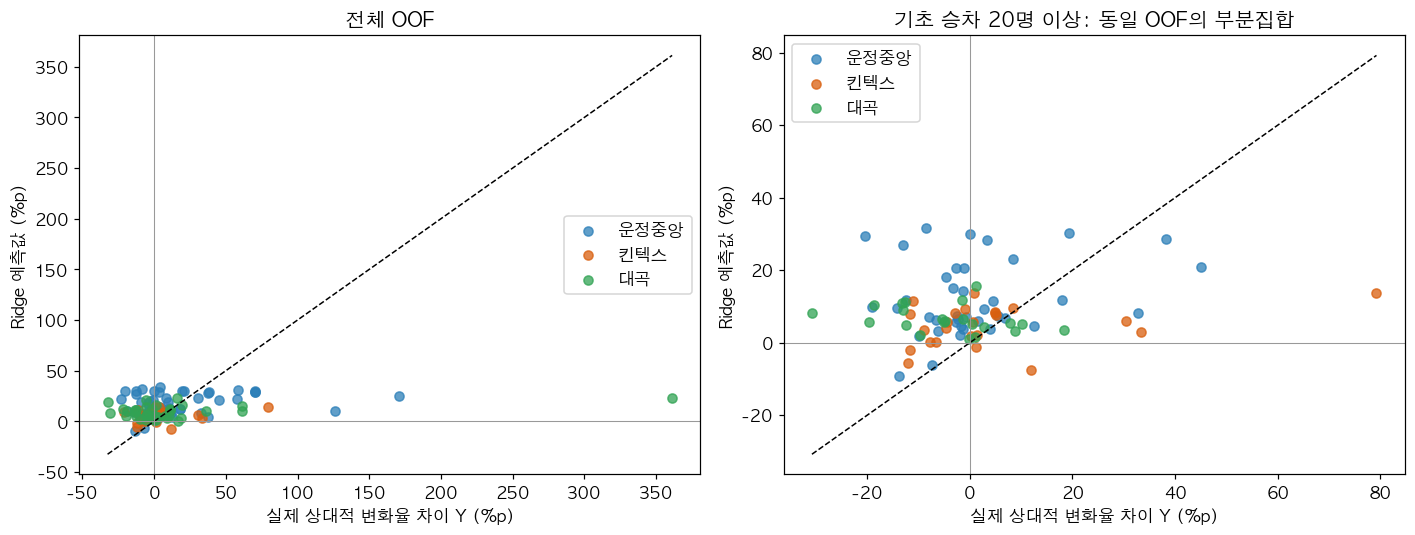

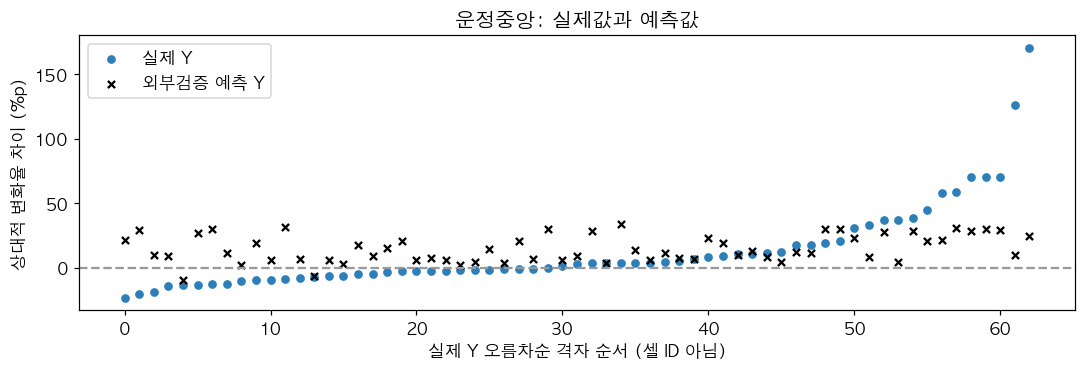

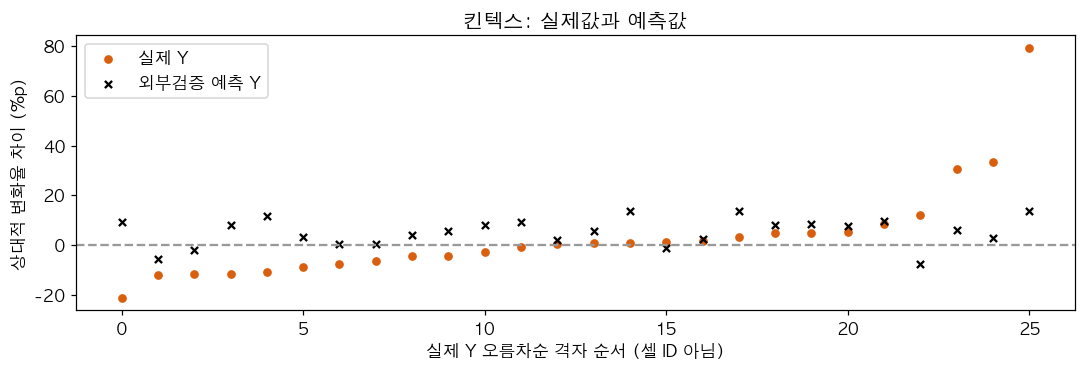

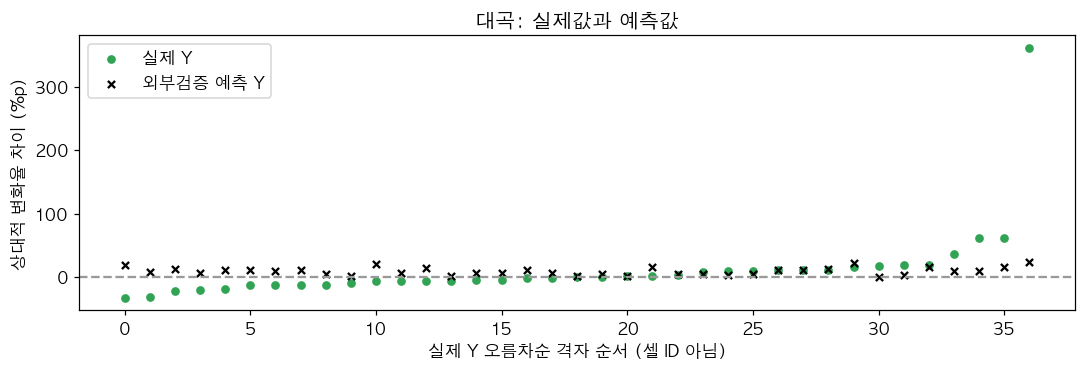

,셀 ID,nearest_station,board_2024_all,board_2025_all,R_i,R_s,Y,Ridge,절대오차
89,44,대곡,269.0,91.0,-66.171,-61.251,-4.920,5.745,10.665
90,1235,대곡,6.0,1.0,-83.333,-61.251,-22.082,12.084,34.167
91,1518,대곡,3.0,1.0,-66.667,-61.251,-5.416,20.838,26.254
92,1712,대곡,43.0,16.0,-62.791,-61.251,-1.540,11.711,13.251
93,1713,대곡,111.0,46.0,-58.559,-61.251,2.692,4.470,1.778
94,1962,대곡,4.0,4.0,0.000,-61.251,61.251,10.346,50.905
95,2477,대곡,130.0,34.0,-73.846,-61.251,-12.595,11.173,23.769
96,2716,대곡,73.0,29.0,-60.274,-61.251,0.977,1.458,0.481
97,2718,대곡,99.0,26.0,-73.737,-61.251,-12.486,4.862,17.349
98,3424,대곡,64.0,24.0,-62.500,-61.251,-1.249,6.635,7.884


In [3]:
colors={'운정중앙':'#2C7FB8','킨텍스':'#D95F0E','대곡':'#31A354'}
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,part,title in [(axes[0],oof,'전체 OOF'),(axes[1],oof[oof.board_2024_all>=20],'기초 승차 20명 이상: 동일 OOF의 부분집합')]:
 for station,g in part.groupby('nearest_station',sort=False):
  ax.scatter(g.Y,g.Ridge,label=station,color=colors[station],alpha=.75)
 lo=min(part.Y.min(),part.Ridge.min());hi=max(part.Y.max(),part.Ridge.max())
 ax.plot([lo,hi],[lo,hi],'k--',lw=1);ax.axvline(0,color='#999999',lw=.7);ax.axhline(0,color='#999999',lw=.7)
 ax.set(xlabel='실제 상대적 변화율 차이 Y (%p)',ylabel='Ridge 예측값 (%p)',title=title);ax.legend()
plt.tight_layout();plt.show()
for station,g in oof.groupby('nearest_station',sort=False):
 ordered=g.sort_values(['Y','셀 ID']);x=np.arange(len(ordered))
 fig,ax=plt.subplots(figsize=(10,3.5))
 ax.scatter(x,ordered.Y,color=colors[station],label='실제 Y',s=22)
 ax.scatter(x,ordered.Ridge,color='black',marker='x',label='외부검증 예측 Y',s=22)
 ax.axhline(0,color='#999999',ls='--');ax.set(xlabel='실제 Y 오름차순 격자 순서 (셀 ID 아님)',ylabel='상대적 변화율 차이 (%p)',title=f'{station}: 실제값과 예측값')
 ax.legend();plt.tight_layout();plt.show()
comparison=oof[['셀 ID','nearest_station','board_2024_all','board_2025_all','R_i','R_s','Y','Ridge','절대오차']].sort_values(['nearest_station','셀 ID'])
with pd.option_context('display.max_rows',140):display(comparison.round(3))

## 3. 권역보다 덜 감소한 격자를 높은 순위에 놓는가?

ROC-AUC는 Y>0 격자를 더 높은 점수로 배치하는 정도, Spearman은 연속 Y의 순서 일치도다. 상위 10·20·30%에서 실제 Y>0 비율과 권역 전체 대비 Lift를 함께 본다. 서로 다른 외부역의 예측점수를 하나의 순위로 섞지 않는다.

**수학적 연결:** 기초 승차량과 권역 사전·사후 총량이 양수이면, Y>0은 기존 ‘권역 내 수요 비중 확대’와 같은 정답이다. 즉 분류 방향은 이전과 같고, 이번에는 차이의 **크기**까지 연속형으로 학습하는 것이다. 큰 Y가 큰 잔존승차량을 뜻하지는 않는다.

,검증역,n,Y>0 격자수,Y>0 비율,ROC_AUC(Y>0),Spearman(연속Y)
0,운정중앙,63,34,0.5397,0.6744,0.2908
1,킨텍스,26,14,0.5385,0.5952,0.2219
2,대곡,37,18,0.4865,0.5117,0.0591


,검증역,상위비율,K,Y>0 격자수,Precision,Lift,실제Y중앙값,실제Y평균
0,운정중앙,0.1,7,5,0.7143,1.3235,3.8926,11.6135
1,운정중앙,0.2,13,10,0.7692,1.4253,19.3964,24.1815
2,운정중앙,0.3,19,15,0.7895,1.4628,20.5592,31.9002
3,킨텍스,0.1,3,3,1.0000,1.8571,3.0634,27.6940
4,킨텍스,0.2,6,4,0.6667,1.2381,1.9140,9.8776
5,킨텍스,0.3,8,5,0.6250,1.1607,1.9140,7.9089
6,대곡,0.1,4,2,0.5000,1.0278,5.1903,84.7832
7,대곡,0.2,8,5,0.6250,1.2847,8.5237,51.9206
8,대곡,0.3,12,6,0.5000,1.0278,-0.1444,32.5332


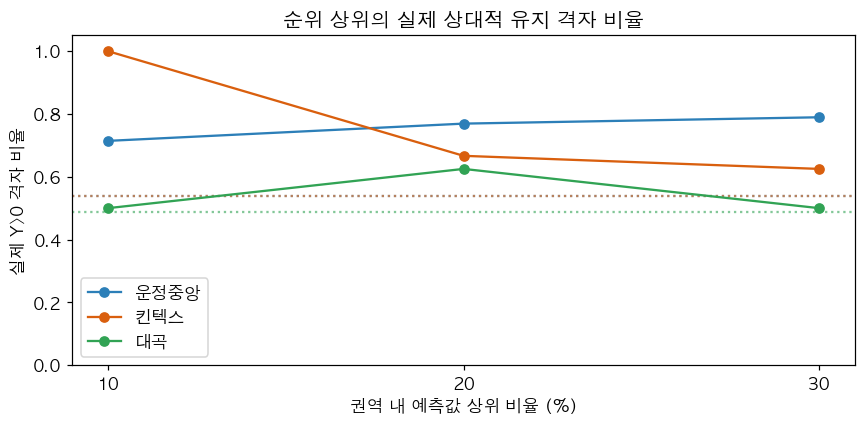

In [4]:
display(ranks.round(4))
display(tops.round(4))
fig,ax=plt.subplots(figsize=(8,4))
for station,g in tops.groupby('검증역',sort=False):
 ax.plot(g['상위비율']*100,g.Precision,marker='o',label=station,color=colors[station])
 ax.axhline(float(ranks.loc[ranks['검증역']==station,'Y>0 비율'].iloc[0]),color=colors[station],ls=':',alpha=.6)
ax.set(xlabel='권역 내 예측값 상위 비율 (%)',ylabel='실제 Y>0 격자 비율',title='순위 상위의 실제 상대적 유지 격자 비율',ylim=(0,1.05));ax.set_xticks([10,20,30]);ax.legend()
plt.tight_layout();plt.show()

## 4. 작은 분모와 극단값 진단

구간은 2024년 승차량 기준으로 고정했다. 결과에 따라 표본을 삭제하거나 구간을 바꾸지 않는다. 절대오차합비중은 해당 집단이 전체 오차에 차지하는 비율이다. 이 부분집합의 R²는 각 부분집합 평균을 기준으로 하므로 전체 R²와 직접 비교해 우열을 정하지 않는다.

,기초승차규모,n,R_i최소,R_i최대,Y중앙값,Y최소,Y최대,절대오차합비중,MAE(%p),RMSE(%p),R2
0,1~4,14,-75.0000,300.0000,36.2510,-5.4157,361.2510,0.3128,57.4288,102.6900,-0.1450
1,5~9,10,-83.3333,55.5556,23.6829,-22.0824,126.1148,0.1085,27.9030,42.0955,-0.1314
2,10~19,17,-93.7500,-11.7647,11.2510,-32.4990,58.7945,0.1187,17.9488,24.3598,-0.2491
3,20명 이상,85,-92.0000,9.5238,-1.4073,-30.7490,79.2539,0.4600,13.9106,18.3101,-0.4222


,셀 ID,nearest_station,board_2024_all,board_2025_all,R_i,R_s,Y,Ridge,절대오차
123,14004,대곡,1.0,4.0,300.000,-61.251,361.251,23.064,338.186
22,7262,운정중앙,1.0,2.0,100.000,-70.559,170.559,24.966,145.594
21,6952,운정중앙,9.0,14.0,55.556,-70.559,126.115,10.289,115.826
86,14062,킨텍스,21.0,23.0,9.524,-69.730,79.254,13.729,65.525
12,4012,운정중앙,4.0,4.0,0.000,-70.559,70.559,28.738,41.821
15,4768,운정중앙,1.0,1.0,0.000,-70.559,70.559,29.756,40.803
27,8635,운정중앙,4.0,4.0,0.000,-70.559,70.559,29.066,41.493
94,1962,대곡,4.0,4.0,0.000,-61.251,61.251,10.346,50.905
104,7368,대곡,3.0,3.0,0.000,-61.251,61.251,15.265,45.986
0,76,운정중앙,17.0,15.0,-11.765,-70.559,58.795,30.717,28.078


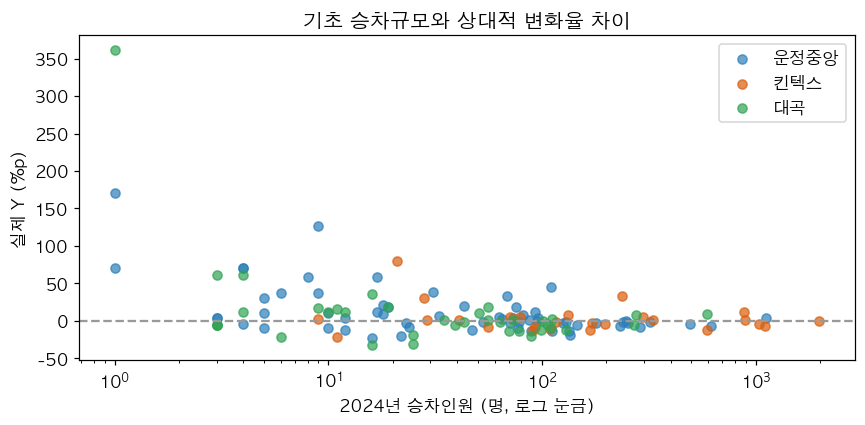

In [5]:
display(size.round(4))
display(oof.loc[oof.Y.abs().nlargest(12).index,['셀 ID','nearest_station','board_2024_all','board_2025_all','R_i','R_s','Y','Ridge','절대오차']].round(3))
fig,ax=plt.subplots(figsize=(8,4))
for station,g in oof.groupby('nearest_station',sort=False):
 ax.scatter(g.board_2024_all,g.Y,label=station,color=colors[station],alpha=.7)
ax.set_xscale('log');ax.axhline(0,color='#999999',ls='--')
ax.set(xlabel='2024년 승차인원 (명, 로그 눈금)',ylabel='실제 Y (%p)',title='기초 승차규모와 상대적 변화율 차이');ax.legend()
plt.tight_layout();plt.show()

## 5. 이번 실행 해석 (2026-10-17)

- 기초 0명 격자는 **0개**, 회귀 표본 **126개**. 0명 회귀 제외 규칙을 구현했지만 이번 표본에서는 제외가 없다.
- 권역 총량 변화율: 운정중앙 −70.559%, 킨텍스 −69.730%, 대곡 −61.251%.
- 전체 Ridge **MAE 20.401%p, RMSE 40.231%p, R² 0.079**. Y=0 기준은 MAE 19.167%p, RMSE 43.218%p. Ridge는 RMSE를 줄였지만 MAE는 증가했다. 학습평균 기준보다는 두 오차가 작다. 단일 지표로 우수하다고 확정하지 않는다.
- 역별 Ridge MAE: 운정중앙 20.739%p, 킨텍스 13.045%p, 대곡 24.996%p. 세 역 모두 Y=0 기준보다 MAE가 컸다.
- 순위 ROC-AUC는 운정중앙 0.674, 킨텍스 0.595, 대곡 0.512. 운정중앙의 신호가 상대적으로 크지만 대곡으로 재현된다는 근거는 약하다.
- 기초 1~4명인 14개가 전체 절대오차의 약 **31.3%**를 차지했다. 대곡의 1→4명 격자는 R_i=+300%, Y=+361.251%p로 여전히 극단적이다. 권역 변화율을 빼는 것만으로 작은 분모 문제가 해결되지는 않았다.
- 현재 실험은 상대적 차이의 연속 예측 가능성을 점검한 결과이며 최종모형 선정이 아니다. 새 변수·대상·모델을 같은 세 역에서 반복 선택하면 낙관적 편향이 남는다.
- GTX-C에서는 실제 개통 후 권역 총량을 알 수 없으므로 이 출력만으로 개통 후 승차인원이나 절대 변화율을 복원할 수 없다. 이번 실험에서 C 적용을 수행하지 않았다.